# Privacy-Preserving Training of a PIN-Code Digit Recogniser
Responsible and Safe AI (AIML4001) - External Practical, Set D
Enrollment No.: 23IT021 | Date: 25/11/2026

Dataset: MNIST handwritten digits (random 20,000-image training subset, seed 42; full 10,000-image test set).
Settings: torch.manual_seed(42), GroupNorm, delta = 1e-5, max_grad_norm = 1.0, batch size 256, 3 epochs, CPU.

## Setup - imports, configuration, data and helper functions

In [1]:
import json, time, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import opacus
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 42
DEVICE = torch.device("cpu")
BATCH_SIZE = 256
EPOCHS = 3
LR = 1e-3                      # Adam learning rate (same for all models)
DELTA = 1e-5
MAX_GRAD_NORM = 1.0            # clipping bound C
TARGET_EPSILONS = [10.0, 5.0, 1.0]
FIXED_NOISE = 1.1
SUBSET_SIZE = 20_000
ACCOUNTANT = "rdp"             # Renyi-DP accountant

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

T0 = time.time()
print("torch", torch.__version__, "| opacus", opacus.__version__, "| device", DEVICE)

torch 2.15.0+cpu | opacus 1.6.0 | device cpu


In [2]:
# MNIST + 20,000-image training subset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
full_train = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_set   = datasets.MNIST("./data", train=False, download=True, transform=transform)

g = torch.Generator().manual_seed(SEED)
subset_idx = torch.randperm(len(full_train), generator=g)[:SUBSET_SIZE]
train_set = Subset(full_train, subset_idx.tolist())

test_loader       = DataLoader(test_set,  batch_size=1024, shuffle=False)
train_eval_loader = DataLoader(train_set, batch_size=1024, shuffle=False)

def make_train_loader():
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=gen)

print("Train subset:", len(train_set), "images | Test set:", len(test_set), "images")

Train subset: 20000 images | Test set: 10000 images


In [3]:
# Training / evaluation helpers
def train_one_epoch(model, loader, optimizer):
    model.train()
    for x, y in loader:
        if len(y) == 0:            # Poisson sampling (DP loader) can give an empty batch
            continue
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x.to(DEVICE)), y.to(DEVICE))
        loss.backward()
        optimizer.step()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        correct += (model(x.to(DEVICE)).argmax(1) == y.to(DEVICE)).sum().item()
        total += len(y)
    return 100.0 * correct / total

@torch.no_grad()
def mean_confidence(model, loader):
    """Mean max-softmax probability over a dataset (membership-inference signal)."""
    model.eval()
    confs = [F.softmax(model(x.to(DEVICE)), dim=1).max(1).values for x, _ in loader]
    return torch.cat(confs).mean().item()

## Task 1 - GroupNorm CNN and non-private baseline

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.gn1   = nn.GroupNorm(4, 16)          # GroupNorm instead of BatchNorm (Opacus)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.gn2   = nn.GroupNorm(8, 32)
        self.fc1   = nn.Linear(32 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.gn1(self.conv1(x))), 2)   # 28 -> 14
        x = F.max_pool2d(F.relu(self.gn2(self.conv2(x))), 2)   # 14 -> 7
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

m = SmallCNN()
print(m)
print("Trainable parameters:", sum(p.numel() for p in m.parameters()))
print("Opacus ModuleValidator errors:", ModuleValidator.validate(m, strict=False))

SmallCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (gn1): GroupNorm(4, 16, eps=1e-05, affine=True, bias=True)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (gn2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 207018
Opacus ModuleValidator errors: []


In [5]:
set_seed()
baseline = SmallCNN().to(DEVICE)
opt = torch.optim.Adam(baseline.parameters(), lr=LR)
loader = make_train_loader()
for epoch in range(1, EPOCHS + 1):
    train_one_epoch(baseline, loader, opt)
    print(f"[baseline] epoch {epoch}: test acc {evaluate(baseline, test_loader):.2f} %")
base_acc = evaluate(baseline, test_loader)
print(f"\nBaseline (no DP)  : test accuracy {base_acc:.1f} %")

[baseline] epoch 1: test acc 95.73 %


[baseline] epoch 2: test acc 97.05 %


[baseline] epoch 3: test acc 97.78 %



Baseline (no DP)  : test accuracy 97.8 %


## Task 2 - DP models with make_private_with_epsilon (target eps = 10, 5, 1)

In [6]:
def train_dp(target_eps=None, noise_multiplier=None):
    """DP-SGD training with Opacus. Pass target_eps (make_private_with_epsilon)
    or a fixed noise_multiplier (make_private). Returns model, test acc, eps after each epoch, sigma."""
    set_seed()
    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    engine = PrivacyEngine(accountant=ACCOUNTANT)
    loader = make_train_loader()
    if target_eps is not None:
        model, optimizer, loader = engine.make_private_with_epsilon(
            module=model, optimizer=optimizer, data_loader=loader,
            target_epsilon=target_eps, target_delta=DELTA,
            epochs=EPOCHS, max_grad_norm=MAX_GRAD_NORM)
    else:
        model, optimizer, loader = engine.make_private(
            module=model, optimizer=optimizer, data_loader=loader,
            noise_multiplier=noise_multiplier, max_grad_norm=MAX_GRAD_NORM)
    eps_hist = []
    for epoch in range(1, EPOCHS + 1):
        train_one_epoch(model, loader, optimizer)
        eps_hist.append(engine.get_epsilon(DELTA))
        print(f"  epoch {epoch}: eps spent = {eps_hist[-1]:.2f}")
    return model, evaluate(model, test_loader), eps_hist, optimizer.noise_multiplier

dp_results, dp_models = [], {}
for eps in TARGET_EPSILONS:
    print(f"[DP] target eps = {eps}")
    model, acc, eps_hist, sigma = train_dp(target_eps=eps)
    dp_models[eps] = model
    dp_results.append({"target_eps": eps, "acc": acc, "eps_spent": eps_hist[-1],
                       "eps_per_epoch": eps_hist, "noise_multiplier": sigma})
    print(f"  -> noise_multiplier = {sigma:.3f}, test acc = {acc:.2f} %\n")

[DP] target eps = 10.0


  epoch 1: eps spent = 7.66


  epoch 2: eps spent = 8.98


  epoch 3: eps spent = 9.99


  -> noise_multiplier = 0.521, test acc = 93.98 %

[DP] target eps = 5.0


  epoch 1: eps spent = 3.99


... (3 outputs left out)

  epoch 1: eps spent = 0.80


  epoch 2: eps spent = 0.91


  epoch 3: eps spent = 0.99


  -> noise_multiplier = 1.235, test acc = 90.29 %



In [7]:
# Part A - accuracy at different privacy budgets
print(f"Baseline (no DP)  : test accuracy {base_acc:.1f} %\n")
print("TARGET_EPS   DELTA    CLIP(C)   EPOCHS   TEST_ACC   EPS_SPENT   NOISE(sigma)")
print("-" * 78)
for r in dp_results:
    print(f"  {r['target_eps']:5.1f}     {DELTA:.0e}    {MAX_GRAD_NORM:.1f}       {EPOCHS}       "
          f"{r['acc']:5.1f} %     {r['eps_spent']:5.2f}       {r['noise_multiplier']:.3f}")
print("-" * 78)
acc_eps1 = next(r["acc"] for r in dp_results if r["target_eps"] == 1.0)
cost = acc_eps1 - base_acc
print(f"Accuracy cost of strongest privacy (eps = 1) : {cost:+.1f} %")

Baseline (no DP)  : test accuracy 97.8 %

TARGET_EPS   DELTA    CLIP(C)   EPOCHS   TEST_ACC   EPS_SPENT   NOISE(sigma)
------------------------------------------------------------------------------
   10.0     1e-05    1.0       3        94.0 %      9.99       0.521
    5.0     1e-05    1.0       3        93.2 %      5.00       0.662
    1.0     1e-05    1.0       3        90.3 %      0.99       1.235
------------------------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -7.5 %


## Task 3 - Fixed noise_multiplier = 1.1, eps recorded after each epoch

In [8]:
_, fixed_acc, fixed_eps, _ = train_dp(noise_multiplier=FIXED_NOISE)
print(f"\nFIXED noise_multiplier = {FIXED_NOISE}")
print("EPOCH   EPSILON_SPENT")
print("-" * 21)
for i, e in enumerate(fixed_eps, 1):
    print(f"  {i}       {e:.2f}")
print("-" * 21)
print(f"(test accuracy of this model: {fixed_acc:.1f} %)")

  epoch 1: eps spent = 1.04


  epoch 2: eps spent = 1.17


  epoch 3: eps spent = 1.28



FIXED noise_multiplier = 1.1
EPOCH   EPSILON_SPENT
---------------------
  1       1.04
  2       1.17
  3       1.28
---------------------
(test accuracy of this model: 91.0 %)


## Task 4 - Membership-inference check (mean max-softmax confidence, train vs test)

In [9]:
b_tr, b_te = mean_confidence(baseline, train_eval_loader), mean_confidence(baseline, test_loader)
d_tr, d_te = mean_confidence(dp_models[1.0], train_eval_loader), mean_confidence(dp_models[1.0], test_loader)
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print("MODEL         TRAIN    TEST     GAP")
print("-" * 35)
print(f"Baseline      {b_tr:.3f}    {b_te:.3f}    {b_tr - b_te:.3f}")
print(f"DP (eps=1)    {d_tr:.3f}    {d_te:.3f}    {d_tr - d_te:.3f}")
print("-" * 35)

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL         TRAIN    TEST     GAP
-----------------------------------
Baseline      0.972    0.970    0.002
DP (eps=1)    0.891    0.897    -0.006
-----------------------------------


## Task 5 - Plots: test accuracy vs eps, and eps vs epoch

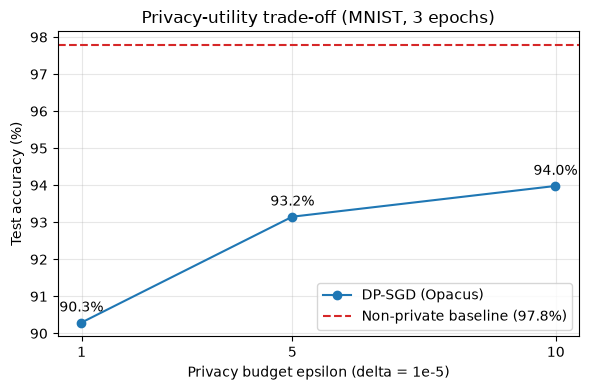

Plot saved : accuracy_vs_epsilon.png


In [10]:
xs = [r["eps_spent"] for r in dp_results][::-1]
ys = [r["acc"] for r in dp_results][::-1]
plt.figure(figsize=(6, 4))
plt.plot(xs, ys, "o-", color="tab:blue", label="DP-SGD (Opacus)")
for x, y in zip(xs, ys):
    plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.axhline(base_acc, color="tab:red", ls="--", label=f"Non-private baseline ({base_acc:.1f}%)")
plt.xlabel("Privacy budget epsilon (delta = 1e-5)")
plt.ylabel("Test accuracy (%)")
plt.title("Privacy-utility trade-off (MNIST, 3 epochs)")
plt.xticks([1, 5, 10]); plt.grid(alpha=0.3); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

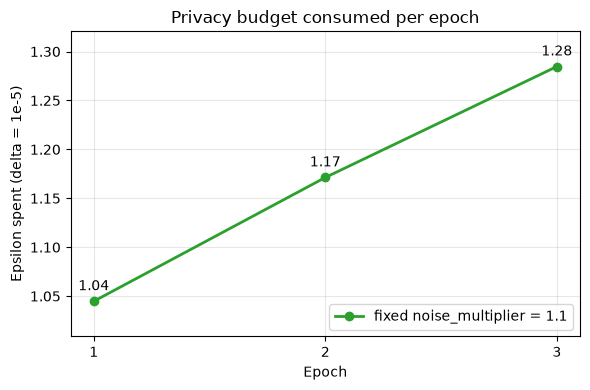

Plot saved : epsilon_vs_epoch.png


In [11]:
epochs = list(range(1, EPOCHS + 1))
plt.figure(figsize=(6, 4))
plt.plot(epochs, fixed_eps, "o-", color="tab:green", lw=2, label=f"fixed noise_multiplier = {FIXED_NOISE}")
for x, y in zip(epochs, fixed_eps):
    plt.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("Epoch"); plt.ylabel("Epsilon spent (delta = 1e-5)")
plt.title("Privacy budget consumed per epoch")
pad = 0.15 * (max(fixed_eps) - min(fixed_eps) + 1e-9)
plt.ylim(min(fixed_eps) - pad, max(fixed_eps) + pad)
plt.xticks(epochs); plt.grid(alpha=0.3); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("epsilon_vs_epoch.png", dpi=150)
plt.show()
print("Plot saved : epsilon_vs_epoch.png")

## Task 6 - Results table and eps recommendation
Rule used: recommend the smallest eps (strongest privacy) whose test accuracy is within 5 percentage points
of the non-private baseline.

In [12]:
print("MODEL                 EPS_SPENT   NOISE(sigma)   TEST_ACC   DROP_vs_BASE")
print("-" * 72)
print(f"Baseline (no DP)        -            -          {base_acc:5.1f} %      -")
for r in dp_results:
    print(f"DP target eps={r['target_eps']:<5g}    {r['eps_spent']:5.2f}       {r['noise_multiplier']:.3f}        "
          f"{r['acc']:5.1f} %    {r['acc'] - base_acc:+.1f} %")
print(f"DP fixed sigma={FIXED_NOISE}      {fixed_eps[-1]:5.2f}       {FIXED_NOISE:.3f}        "
      f"{fixed_acc:5.1f} %    {fixed_acc - base_acc:+.1f} %")
print("-" * 72)

THRESH = 5.0
ok = [r for r in dp_results if base_acc - r["acc"] <= THRESH]
rec = min(ok, key=lambda r: r["target_eps"]) if ok else max(dp_results, key=lambda r: r["acc"])
print(f"Recommended eps : {rec['target_eps']:g}  ({rec['acc'] - base_acc:+.1f} % accuracy vs baseline)")

results = {"baseline_acc": base_acc, "dp_results": dp_results,
           "fixed_noise": {"noise_multiplier": FIXED_NOISE, "eps_per_epoch": fixed_eps, "acc": fixed_acc},
           "membership": {"baseline": [b_tr, b_te, b_tr - b_te], "dp_eps1": [d_tr, d_te, d_tr - d_te]},
           "accuracy_cost_eps1": cost, "recommended_eps": rec["target_eps"],
           "versions": {"torch": torch.__version__, "opacus": opacus.__version__},
           "runtime_sec": time.time() - T0}
json.dump(results, open("results.json", "w"), indent=2)
print(f"Total runtime: {time.time() - T0:.0f} s  |  results saved to results.json")

MODEL                 EPS_SPENT   NOISE(sigma)   TEST_ACC   DROP_vs_BASE
------------------------------------------------------------------------
Baseline (no DP)        -            -           97.8 %      -
DP target eps=10        9.99       0.521         94.0 %    -3.8 %
DP target eps=5         5.00       0.662         93.2 %    -4.6 %
DP target eps=1         0.99       1.235         90.3 %    -7.5 %
DP fixed sigma=1.1       1.28       1.100         91.0 %    -6.7 %
------------------------------------------------------------------------
Recommended eps : 5  (-4.6 % accuracy vs baseline)
Total runtime: 420 s  |  results saved to results.json
